# Random vs QD behaviour-tree coverage analysis

Compares **random** search campaigns (`random_tests/`) against **Quality-Diversity
(MAP-Elites)** campaigns (`optimization_tests/`) across three Nav2 behaviour-tree
tasks and two maps.  The goal is to determine whether QD actually yields higher
behaviour-tree coverage than a random baseline, and if not, why.

### Setup

Reuses the proven loading / coverage functions from `bt_coverage_analysis.ipynb`.
Targets: pandas, numpy, matplotlib, seaborn, scipy.

In [1]:
from __future__ import annotations
import json, sqlite3, csv
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

mpl.rcParams.update({
    "figure.dpi": 140,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
})
sns.set_style("whitegrid")

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
OPT_ROOT  = DATA_ROOT / "optimization_tests"
RND_ROOT  = DATA_ROOT / "random_tests"
CACHE     = DATA_ROOT / "bt_coverage_cache"
CACHE.mkdir(exist_ok=True)

/home/sam/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


/home/sam/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


### Campaign registry

In [2]:
# QD campaigns come from optimization_tests/<suffix>.incomplete/<suffix> (double-nested)
# Random campaigns come from random_tests/experiment-qd-<suffix> (flat)
# Keys are unique ids "<strategy>:<display label>" so QD and Random can share a label.

OPT_CAMPAIGNS = {
    "nav_to_pose · hex":    "qd-nav-to-pose-hexagon-2026-09-08-01141390",
    "nav_to_pose · sec":    "qd-nav-to-pose-secorolab-2026-09-08-01140915",
    "nav_through · hex":    "qd-nav-through-poses-hexagon-2026-09-08-01142436",
    "nav_through · sec":    "qd-nav-through-poses-secorolab-2026-09-08-01141901",
    "follow_wp · hex":      "qd-follow-waypoints-hexagon-2026-09-08-01143461",
    "follow_wp · sec":      "qd-follow-waypoints-secorolab-2026-09-08-01142971",
}

RND_CAMPAIGNS = {
    "nav_to_pose · hex":    "experiment-qd-nav-to-pose-hexagon-2026-09-15-13061176",
    "nav_through · hex":    "experiment-qd-nav-through-poses-hexagon-2026-09-16-02255762",
    "nav_through · sec":    "experiment-qd-nav-through-poses-secorolab-2026-09-15-18454090",
    "follow_wp · hex":      "experiment-qd-follow-waypoints-hexagon-2026-09-16-09484561",
}

def _opt_root(suffix):
    return OPT_ROOT / f"{suffix}.incomplete" / suffix

def _rnd_root(suffix):
    return RND_ROOT / suffix

def _campaign_root(strategy, suffix):
    return _opt_root(suffix) if strategy == "qd" else _rnd_root(suffix)

ALL_CAMPAIGNS = {}
for strat, labels in (("qd", OPT_CAMPAIGNS), ("rnd", RND_CAMPAIGNS)):
    for label, suf in labels.items():
        ALL_CAMPAIGNS[f"{strat}:{label}"] = (strat, label, suf)

print(f"Total campaigns: {len(ALL_CAMPAIGNS)}  (QD: {len(OPT_CAMPAIGNS)}, Random: {len(RND_CAMPAIGNS)})")
for k, (strat, label, suf) in sorted(ALL_CAMPAIGNS.items()):
    root = _campaign_root(strat, suf)
    exists = root.exists()
    print(f"  {strat:3s}  {label:28s}  {'OK' if exists else 'MISSING'}  {root.name if exists else '(missing)'}")

Total campaigns: 10  (QD: 6, Random: 4)
  qd   follow_wp · hex               OK  qd-follow-waypoints-hexagon-2026-09-08-01143461
  qd   follow_wp · sec               OK  qd-follow-waypoints-secorolab-2026-09-08-01142971
  qd   nav_through · hex             OK  qd-nav-through-poses-hexagon-2026-09-08-01142436
  qd   nav_through · sec             OK  qd-nav-through-poses-secorolab-2026-09-08-01141901
  qd   nav_to_pose · hex             OK  qd-nav-to-pose-hexagon-2026-09-08-01141390
  qd   nav_to_pose · sec             OK  qd-nav-to-pose-secorolab-2026-09-08-01140915
  rnd  follow_wp · hex               OK  experiment-qd-follow-waypoints-hexagon-2026-09-16-09484561
  rnd  nav_through · hex             OK  experiment-qd-nav-through-poses-hexagon-2026-09-16-02255762
  rnd  nav_through · sec             OK  experiment-qd-nav-through-poses-secorolab-2026-09-15-18454090
  rnd  nav_to_pose · hex             OK  experiment-qd-nav-to-pose-hexagon-2026-09-15-13061176


In [3]:
import xml.etree.ElementTree as ET

def parse_bt_xml(xml_path):
    '''Flatten a BehaviourTree.CPP XML tree into {{names, parents, classes, declared}}.'''
    tree = ET.parse(xml_path)
    root = tree.getroot()
    names, parents, classes = [], {}, {}
    def _walk(elem, parent=None):
        tag = elem.tag
        name = elem.get("name", tag)
        names.append(name)
        parents[name] = parent
        classes[name] = tag
        for child in elem:
            if child.tag == "SubTree":
                subtree_name = child.get("ID", child.get("name", ""))
                names.append(subtree_name)
                parents[subtree_name] = name
                classes[subtree_name] = "SubTree"
            else:
                _walk(child, name)
    _walk(root)
    return {"names": list(dict.fromkeys(names)),
            "parents": parents, "classes": classes,
            "declared": set(names)}

In [4]:
def load_campaign(key, max_units=None):
    '''Return a campaign dict from campaign.db (config_json lives on the campaign table).
       If max_units is set, keep only that many unique unit configs (sorted by batch_id then config_name).'''
    strat, label, suffix = ALL_CAMPAIGNS[key]
    root = _campaign_root(strat, suffix)
    db_path = root / "campaign.db"
    conn = sqlite3.connect(db_path)
    units = pd.read_sql("SELECT * FROM unit", conn)
    runs  = pd.read_sql("SELECT * FROM run",  conn)
    camp  = pd.read_sql("SELECT * FROM campaign", conn)
    conn.close()

    cfg = json.loads(camp.iloc[0]["config_json"])
    bt_rel = cfg["search"]["extract"]["params"]["bt_xml"]
    bt_xml = root / "_config" / bt_rel
    tree = parse_bt_xml(bt_xml)

    # --- unit cap: keep only the first N unique configs (some config_name entries are empty) ---
    if max_units and units["config_name"].astype(str).str.strip().nunique() > max_units:
        _ord = units.sort_values(["batch_id", "id"]).reset_index(drop=True)
        keep = []
        seen = set()
        for cfg in _ord["config_name"]:
            cfg_s = str(cfg).strip()
            if not cfg_s or cfg_s in seen:
                continue
            seen.add(cfg_s)
            keep.append(cfg_s)
            if len(keep) >= max_units:
                break
        units = units[units["config_name"].astype(str).str.strip().isin(keep)].copy()
        runs  = runs[runs["unit_id"].isin(units["id"])].copy()

    return {
        "name": label, "strategy": strat, "root": root,
        "units": units, "runs": runs, "tree": tree,
        "declared": tree["declared"],
        "bt_xml": bt_xml,
        "n_units": len(units),
        "n_runs": len(runs),
        "params_json": cfg,
    }

In [5]:
def _key(label, strat):
    return f"{strat}:{label}"

# Fair comparison: cap every campaign at the same number of UNIQUE configurations.
# QD already uses 120 units; random is capped to its first 120 as well.
MAX_UNITS = 120

campaigns = {}
for key in ALL_CAMPAIGNS:
    try:
        campaigns[key] = load_campaign(key, max_units=MAX_UNITS)
        c = campaigns[key]
        print(f"OK {c['name']:28s}  {c['n_units']:>4d} units  {c['n_runs']:>4d} runs  "
              f"|declared|={len(c['declared'])}")
    except Exception as e:
        print(f"ERR {key:40s}  {type(e).__name__}: {e}")

OK nav_to_pose · hex              120 units   600 runs  |declared|=24
OK nav_to_pose · sec              120 units   600 runs  |declared|=24
OK nav_through · hex              120 units   590 runs  |declared|=26
OK nav_through · sec              120 units   600 runs  |declared|=26
OK follow_wp · hex                120 units   490 runs  |declared|=24
OK follow_wp · sec                120 units   600 runs  |declared|=24
OK nav_to_pose · hex              120 units   120 runs  |declared|=24
OK nav_through · hex              120 units   120 runs  |declared|=26
OK nav_through · sec              120 units   120 runs  |declared|=26
OK follow_wp · hex                120 units   120 runs  |declared|=24


### Coverage computation

`coverage = |{BT nodes reached (non-IDLE)} ∩ declared| / |declared|`
where *declared* is the set of distinct node names in the behaviour-tree XML.

In [6]:
from rosbags.highlevel import AnyReader

def _bag_reached(bag_dir):
    '''Set of non-IDLE node names from a behaviour-tree-log bag.'''
    reached = set()
    bag = Path(bag_dir)
    if not (bag / "rosbag2_0.mcap").exists():
        return reached
    try:
        with AnyReader([bag]) as reader:
            for conn, _ts, raw in reader.messages(
                    connections=[c for c in reader.connections
                                 if c.topic == "/behavior_tree_log"]):
                msg = reader.deserialize(raw, conn.msgtype)
                for ev in msg.event_log:
                    if ev.current_status and ev.current_status != "IDLE":
                        reached.add(ev.node_name)
    except Exception:
        pass
    return reached


def load_reached_all(camp, cache_key=None):
    '''Map {bag_dir_str: [reached nodes]} across all runs of a campaign (JSON cache).'''
    cache_path = CACHE / ("rndcov_" + (cache_key or camp["name"]).replace(" ", "_").replace("·", "_") + ".json")
    if cache_path.exists():
        return {k: set(v) for k, v in json.loads(cache_path.read_text()).items()}

    reached_map = {}
    root = camp["root"]
    for cfg in sorted(d for d in root.iterdir()
                      if d.is_dir() and d.name.startswith("c")):
        subs = sorted((d.name for d in cfg.iterdir()
                       if (d.is_dir() or d.is_symlink()) and d.name.isdigit()), key=int)
        for sub in subs:
            bag = cfg / sub / "rosbag2"
            if not bag.is_dir():
                continue
            reached = _bag_reached(bag)
            if reached:
                reached_map[str(bag)] = sorted(reached)

    cache_path.write_text(json.dumps(reached_map))
    return {k: set(v) for k, v in reached_map.items()}


def per_run_coverage(camp, cache_key=None):
    '''DataFrame with one row per bag: coverage + metadata.
       Only keeps bags whose unit config is present in camp["units"] (honours max_units cap).'''
    reached_map = load_reached_all(camp, cache_key)
    declared = camp["declared"]
    allowed = set(camp["units"]["config_name"])
    unit_map = {}
    for _, row in camp["units"].iterrows():
        unit_map[row["config_name"]] = {
            "batch": row.get("batch_id"),
            "objective": row.get("objective"),
        }
    rows = []
    for bag_str, rm in reached_map.items():
        bag = Path(bag_str)
        config_name = bag.parent.parent.name          # the unit/cfg dir
        if config_name not in allowed:
            continue
        run_id = int(bag.parent.name)                 # run index (0,1,2,...)
        covered = len(rm & declared) / len(declared)
        meta = unit_map.get(config_name, {})
        rows.append({
            "config_name": config_name, "run_id": run_id,
            "coverage": covered, "n_reached": len(rm & declared),
            "n_declared": len(declared),
            "batch": meta.get("batch"),
            "objective": meta.get("objective"),
        })
    return pd.DataFrame(rows)

In [7]:
print("Loading rosbag coverage for all campaigns...")
run_cov = {}
for key, camp in campaigns.items():
    rc = per_run_coverage(camp, cache_key=key)
    run_cov[key] = rc
    print(f"  {camp['name']:28s}  {len(rc):>4d} bags  mean={rc['coverage'].mean():.3f}  "
          f"max={rc['coverage'].max():.3f}  median={rc['coverage'].median():.3f}")

Loading rosbag coverage for all campaigns...
  nav_to_pose · hex              590 bags  mean=0.425  max=0.917  median=0.292
  nav_to_pose · sec              595 bags  mean=0.488  max=0.917  median=0.292
  nav_through · hex              589 bags  mean=0.664  max=0.846  median=0.846
  nav_through · sec              599 bags  mean=0.679  max=0.923  median=0.846
  follow_wp · hex                425 bags  mean=0.465  max=0.917  median=0.292
  follow_wp · sec                585 bags  mean=0.674  max=0.917  median=0.833
  nav_to_pose · hex              120 bags  mean=0.401  max=0.917  median=0.292
  nav_through · hex              119 bags  mean=0.614  max=0.846  median=0.846
  nav_through · sec              119 bags  mean=0.695  max=0.923  median=0.846
  follow_wp · hex                119 bags  mean=0.478  max=0.917  median=0.292


In [8]:
def _parse_task(label):
    return label.split("·")[0].strip().replace(" ", "_")

def _parse_map(label):
    return label.split("·")[1].strip()

frames = []
for key, rc in run_cov.items():
    strat = campaigns[key]["strategy"]
    label = campaigns[key]["name"]
    task  = _parse_task(label)
    world = _parse_map(label)
    tmp = rc.copy()
    tmp["strategy"] = strat
    tmp["task"] = task
    tmp["map"] = world
    tmp["campaign"] = label
    tmp["campaign_key"] = key
    frames.append(tmp)
master = pd.concat(frames, ignore_index=True)
print(f"Master DataFrame: {len(master)} rows  strategies={sorted(master['strategy'].unique())}")
print(master.groupby(["strategy","task","map"])["coverage"].agg(["count","mean","max"]).round(3))

Master DataFrame: 3860 rows  strategies=['qd', 'rnd']
                          count   mean    max
strategy task        map                     
qd       follow_wp   hex    425  0.465  0.917
                     sec    585  0.674  0.917
         nav_through hex    589  0.664  0.846
                     sec    599  0.679  0.923
         nav_to_pose hex    590  0.425  0.917
                     sec    595  0.488  0.917
rnd      follow_wp   hex    119  0.478  0.917
         nav_through hex    119  0.614  0.846
                     sec    119  0.695  0.923
         nav_to_pose hex    120  0.401  0.917


## 1. Unit-level coverage: mean and max per campaign

In [9]:
def _camp_summary(label):
    rc = pd.concat([run_cov[k] for k in campaigns if campaigns[k]["name"] == label])
    g = rc.groupby("config_name")["coverage"]
    strat = next(campaigns[k]["strategy"] for k in campaigns if campaigns[k]["name"] == label)
    return {
        "campaign": label,
        "strategy": strat,
        "task": _parse_task(label),
        "map": _parse_map(label),
        "n_units": rc["config_name"].nunique(),
        "n_bags": len(rc),
        "mean": g.mean().mean(),
        "std": g.mean().std(),
        "median": g.mean().median(),
        "p90": g.mean().quantile(0.9),
        "max": g.max().max(),
        "best_unit_mean": g.mean().max(),
    }

all_labels = sorted({campaigns[k]["name"] for k in campaigns})
summary = pd.DataFrame([_camp_summary(l) for l in all_labels])
summary = summary.sort_values(["task", "map", "strategy"])
summary.round(3)

,campaign,strategy,task,map,n_units,n_bags,mean,std,median,p90,max,best_unit_mean
0,follow_wp · hex,qd,follow_wp,hex,204,544,0.472,0.243,0.292,0.850,0.917,0.917
1,follow_wp · sec,qd,follow_wp,sec,117,585,0.674,0.224,0.767,0.883,0.917,0.917
2,nav_through · hex,qd,nav_through,hex,237,708,0.638,0.239,0.846,0.846,0.846,0.846
3,nav_through · sec,qd,nav_through,sec,239,718,0.687,0.216,0.769,0.923,0.923,0.923
4,nav_to_pose · hex,qd,nav_to_pose,hex,238,710,0.413,0.204,0.292,0.833,0.917,0.917
5,nav_to_pose · sec,qd,nav_to_pose,sec,119,595,0.488,0.242,0.342,0.875,0.917,0.917


## 2. Distribution of unit-level coverage

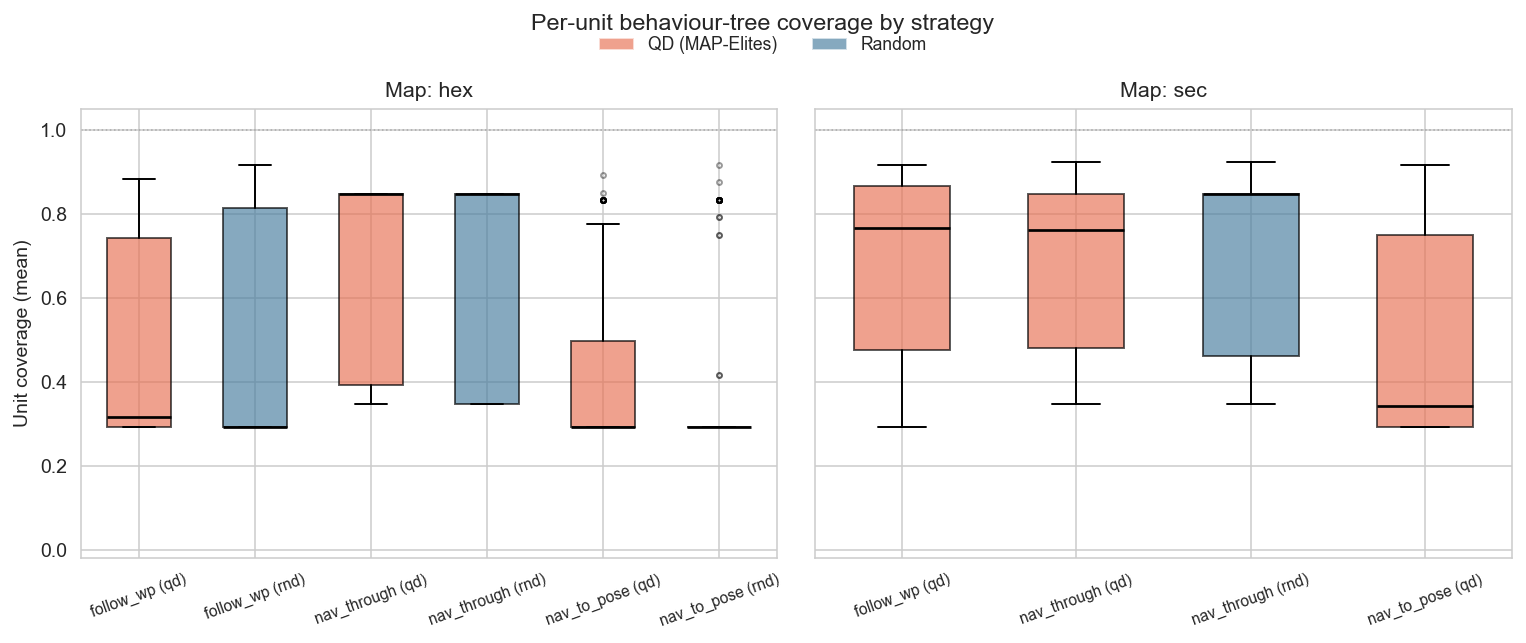

In [10]:
# Per-unit mean coverage, faceted by map
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

unit_means = master.groupby(["campaign_key", "config_name"]).agg(
    coverage=("coverage", "mean"),
    strategy=("strategy", "first"),
    task=("task", "first"),
    map=("map", "first"),
).reset_index()

palette = {"qd": "#e76f51", "rnd": "#457b9d"}

def _display_label(camp_key):
    return campaigns[camp_key]["name"]

for i, world in enumerate(["hex", "sec"]):
    ax = axes[i]
    sub = unit_means[unit_means["map"] == world]
    camps = []
    order = sorted(sub["campaign_key"].unique(),
                   key=lambda k: (_parse_task(_display_label(k)), k))
    data_list = []
    tick_labels = []
    for camp_key in order:
        d = sub[sub["campaign_key"] == camp_key]["coverage"]
        if len(d) == 0:
            continue
        data_list.append(d.values)
        strat = campaigns[camp_key]["strategy"]
        tick_labels.append(_parse_task(_display_label(camp_key)) + " (" + strat + ")")
        camps.append(camp_key)
    bp = ax.boxplot(data_list, tick_labels=tick_labels, patch_artist=True,
                    widths=0.55, showfliers=True, flierprops={"ms": 2.5, "alpha": 0.4})
    for patch, camp_key in zip(bp["boxes"], camps):
        patch.set_facecolor(palette[campaigns[camp_key]["strategy"]])
        patch.set_alpha(0.65)
    for med in bp["medians"]:
        med.set_color("black"); med.set_linewidth(1.4)
    ax.set_title(f"Map: {world}")
    ax.set_ylabel("Unit coverage (mean)" if i == 0 else "")
    ax.set_ylim(-0.02, 1.05)
    ax.axhline(1.0, color="grey", ls=":", lw=0.8, alpha=0.5)
    for tick in ax.get_xticklabels():
        tick.set_fontsize(8)
        tick.set_rotation(20)

fig.suptitle("Per-unit behaviour-tree coverage by strategy", fontsize=12, y=1.01)
legend_handles = [Patch(facecolor=palette["qd"], label="QD (MAP-Elites)", alpha=0.65),
                  Patch(facecolor=palette["rnd"], label="Random", alpha=0.65)]
fig.legend(handles=legend_handles, loc="upper center",
           bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

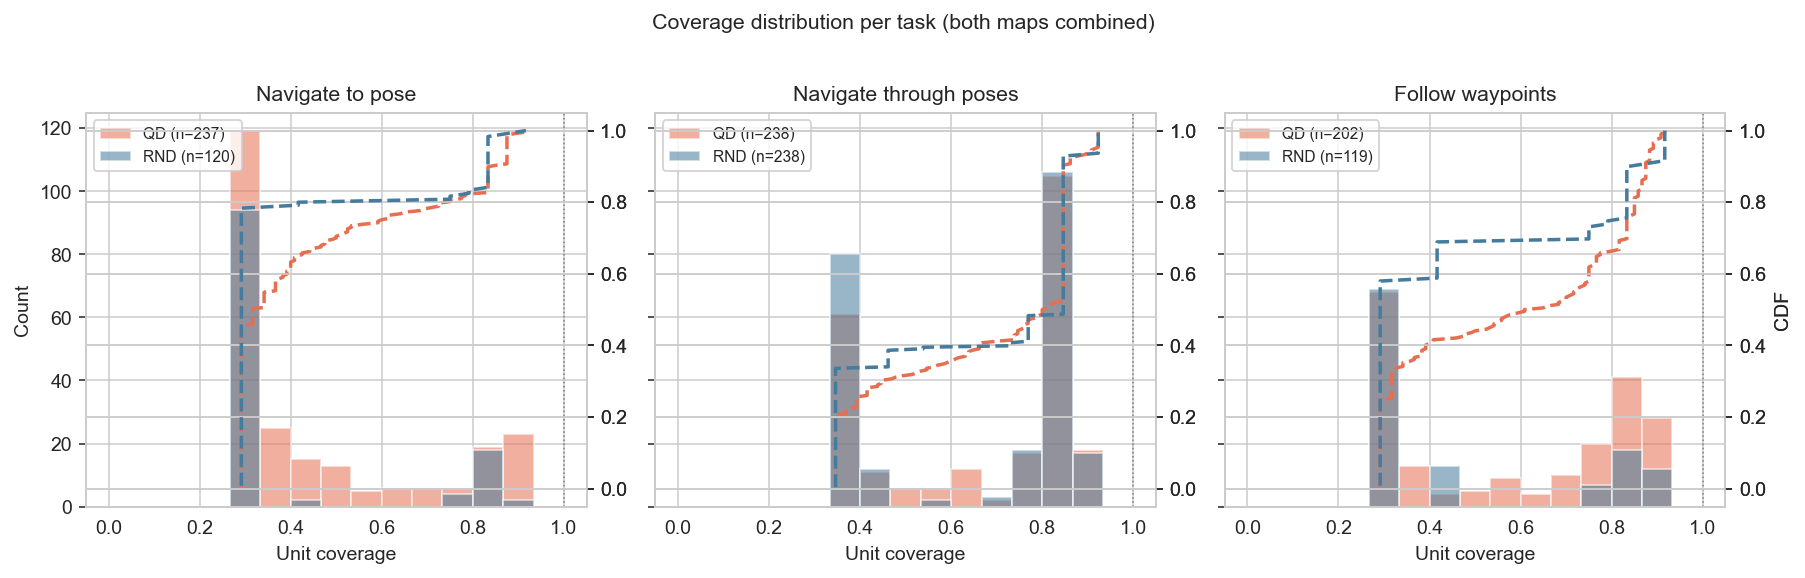

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
tasks = ["nav_to_pose", "nav_through", "follow_wp"]
task_labels = ["Navigate to pose", "Navigate through poses", "Follow waypoints"]

for i, (task, tlabel) in enumerate(zip(tasks, task_labels)):
    ax = axes[i]
    sub = unit_means[unit_means["task"] == task]
    for strat, color in palette.items():
        d = sub[sub["strategy"] == strat]["coverage"]
        if d.empty:
            continue
        ax.hist(d, bins=np.linspace(0, 1, 16), alpha=0.55, color=color,
                edgecolor="white", label=f"{strat.upper()} (n={len(d)})")
        ax2 = ax.twinx()
        d_sorted = np.sort(d.values)
        cdf_y = np.arange(1, len(d_sorted) + 1) / len(d_sorted)
        ax2.plot(d_sorted, cdf_y, color=color, lw=1.8, ls="--")
        ax2.set_ylim(-0.05, 1.05)
        if i == 2:
            ax2.set_ylabel("CDF")
    ax.axvline(1.0, color="grey", ls=":", lw=0.8)
    ax.set_title(tlabel)
    ax.set_xlabel("Unit coverage")
    ax.set_ylabel("Count" if i == 0 else "")
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Coverage distribution per task (both maps combined)", y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

## 3. Head-to-head: QD vs Random on shared tasks × maps

Only campaigns that exist in **both** strategies can be compared directly:

| Campaign | Random | QD |
|---|---|---|
| nav_to_pose · hex | ✓ | ✓ |
| nav_through · hex | ✓ | ✓ |
| nav_through · sec | ✓ | ✓ |
| follow_wp · hex | ✓ | ✓ |
| nav_to_pose · sec | — | QD only |
| follow_wp · sec | — | QD only |

In [12]:
# Shared display labels appear in BOTH strategies (QD and Random) - compare them directly.
shared_tasks = sorted({campaigns[k]["name"] for k in campaigns
                       if campaigns[k]["strategy"] == "rnd"} &
                      {campaigns[k]["name"] for k in campaigns
                       if campaigns[k]["strategy"] == "qd"})

rows = []
for label in shared_tasks:
    task = _parse_task(label)
    world = _parse_map(label)

    rnd_units = unit_means[unit_means["campaign_key"] == _key(label, "rnd")]["coverage"]
    qd_units  = unit_means[unit_means["campaign_key"] == _key(label, "qd")]["coverage"]

    rnd_mean = rnd_units.mean()
    qd_mean  = qd_units.mean()

    if len(rnd_units) > 1 and len(qd_units) > 1:
        U, pval = stats.mannwhitneyu(qd_units, rnd_units, alternative="greater")
    else:
        U, pval = float("nan"), float("nan")

    rows.append({
        "campaign": f"{task} · {world}",
        "QD mean": round(qd_mean, 3),
        "QD max": round(qd_units.max(), 3),
        "QD n": len(qd_units),
        "Rnd mean": round(rnd_mean, 3),
        "Rnd max": round(rnd_units.max(), 3),
        "Rnd n": len(rnd_units),
        "Delta (QD-Rnd)": round(qd_mean - rnd_mean, 3),
        "U": U,
        "p (QD>Rnd)": round(pval, 4) if not np.isnan(pval) else "n/a",
    })

comparison = pd.DataFrame(rows)
comparison

,campaign,QD mean,QD max,QD n,Rnd mean,Rnd max,Rnd n,Delta (QD-Rnd),U,p (QD>Rnd)
0,follow_wp · hex,0.465,0.883,85,0.478,0.917,119,-0.013,5426.5,0.1708
1,nav_through · hex,0.663,0.846,118,0.614,0.846,119,0.049,8010.0,0.0173
2,nav_through · sec,0.679,0.923,120,0.695,0.923,119,-0.016,6666.0,0.8164
3,nav_to_pose · hex,0.425,0.892,118,0.401,0.917,120,0.024,8529.0,0.0007


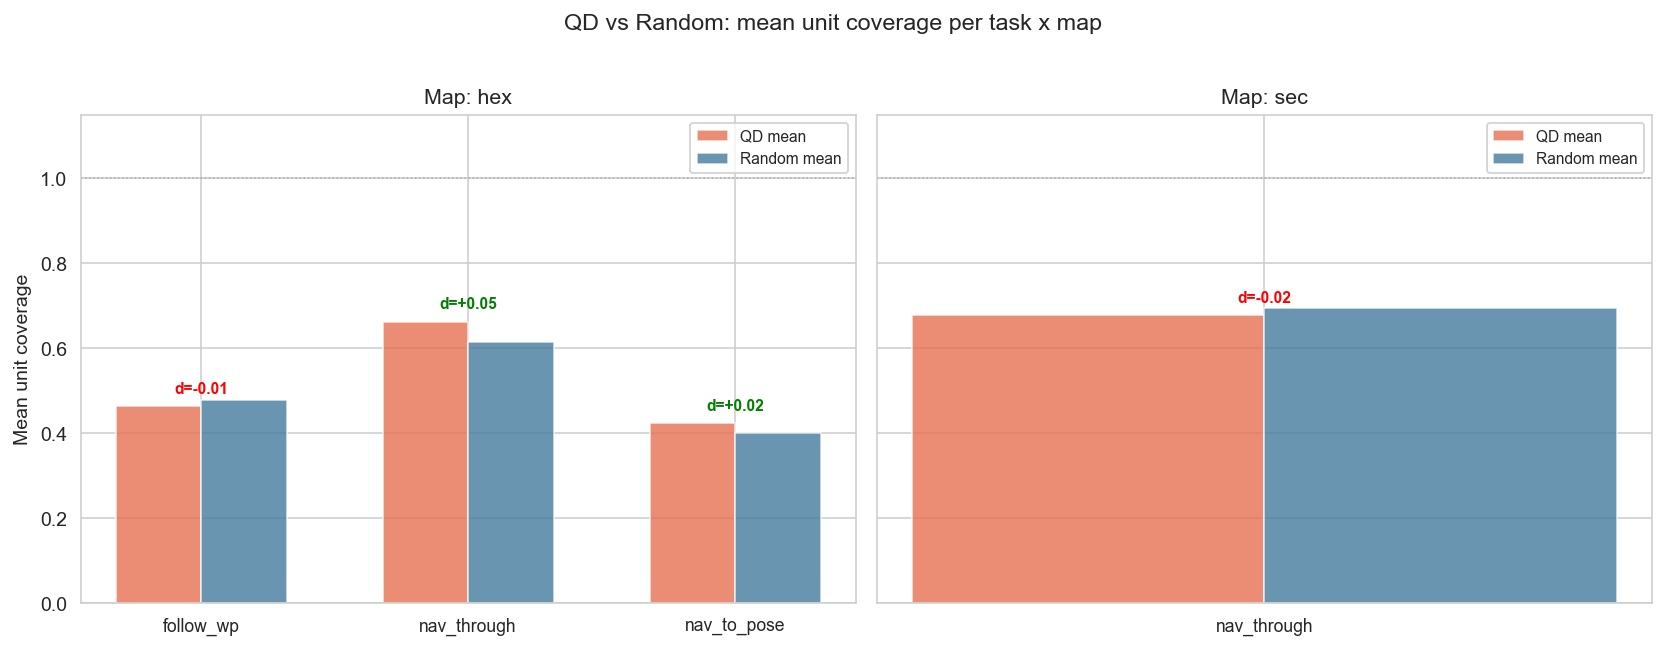

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for i, world in enumerate(["hex", "sec"]):
    ax = axes[i]
    sub = comparison[comparison["campaign"].str.contains(world)]
    if sub.empty:
        ax.set_title(f"Map: {world}  (QD only)")
        ax.text(0.5, 0.5, "No random baseline", transform=ax.transAxes,
                ha="center", va="center", fontsize=12, color="grey")
        continue
    x = np.arange(len(sub))
    w = 0.32
    ax.bar(x - w/2, sub["QD mean"],  w, color=palette["qd"],
           alpha=0.8, label="QD mean", edgecolor="white", linewidth=0.8)
    ax.bar(x + w/2, sub["Rnd mean"], w, color=palette["rnd"],
           alpha=0.8, label="Random mean", edgecolor="white", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([c.split("·")[0].strip() for c in sub["campaign"]], fontsize=9)
    ax.set_title(f"Map: {world}")
    ax.set_ylabel("Mean unit coverage" if i == 0 else "")
    ax.set_ylim(0, 1.15)
    ax.axhline(1.0, color="grey", ls=":", lw=0.8, alpha=0.5)
    for j, (_, row) in enumerate(sub.iterrows()):
        delta = row["Delta (QD-Rnd)"]
        color = "green" if delta > 0 else "red"
        ax.annotate(f"d={delta:+.2f}", (j, row["QD mean"] + 0.03),
                    ha="center", fontsize=8, color=color, fontweight="bold")
    ax.legend(fontsize=8)

fig.suptitle("QD vs Random: mean unit coverage per task x map", y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

## 4. Why might QD not help?

Three hypotheses:

1. **Search budget**: QD used 120 units vs random's ~400 — does QD reach high coverage faster per bag?
2. **Parameter sensitivity**: which BT nodes are hardest to trigger, and does QD explore them more?
3. **Task difficulty**: are some tasks inherently easy (both reach ~100%) or hard (neither does)?

### 4a. Coverage improvement over search budget (convergence)

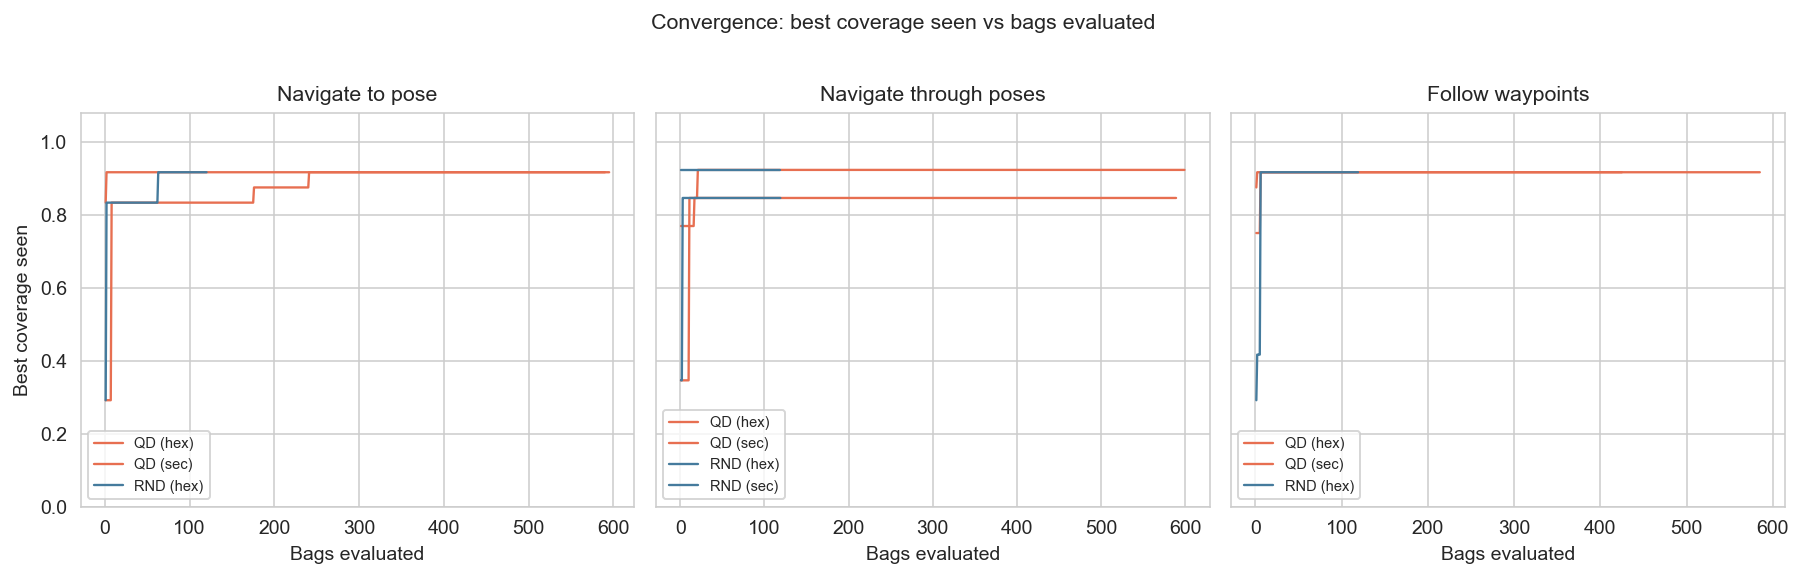

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

for i, (task, tlabel) in enumerate(zip(tasks, task_labels)):
    ax = axes[i]
    for strat, color in palette.items():
        camp_keys = [k for k in campaigns
                     if campaigns[k]["strategy"] == strat
                     and _parse_task(campaigns[k]["name"]) == task]
        if not camp_keys:
            continue
        for camp_key in camp_keys:
            rc = run_cov[camp_key].sort_values(["batch", "config_name", "run_id"]).reset_index()
            best_series = rc["coverage"].expanding().max().values
            world = _parse_map(campaigns[camp_key]["name"])
            ax.plot(np.arange(1, len(best_series) + 1), best_series,
                    color=color, lw=1.2, label=f"{strat.upper()} ({world})")
    ax.set_xlabel("Bags evaluated")
    ax.set_title(tlabel)
    ax.set_ylabel("Best coverage seen" if i == 0 else "")
    ax.set_ylim(0, 1.08)
    ax.legend(fontsize=7.5)

fig.suptitle("Convergence: best coverage seen vs bags evaluated", y=1.02, fontsize=11)
plt.tight_layout()
plt.show()

### 4b. Which BT nodes does each strategy struggle with?

In [15]:
node_tables = {}
for key in campaigns:
    camp = campaigns[key]
    reached_map = load_reached_all(camp, cache_key=key)
    declared = camp["declared"]
    node_frac = {}
    n_bags = len(reached_map)
    for node in declared:
        cnt = sum(1 for rm in reached_map.values() if node in rm)
        node_frac[node] = cnt / n_bags if n_bags else 0.0
    node_tables[key] = node_frac

node_df = pd.DataFrame(node_tables)
node_df.columns = [campaigns[c]["name"] for c in node_df.columns]
print("Per-node fractions (rows=node, cols=campaign):")
node_df.reindex(sorted(node_df.index, key=lambda s: (s in ("NavigateToPose","NavigateThroughPoses","FollowWaypoints"), s)))

Per-node fractions (rows=node, cols=campaign):


,nav_to_pose · hex,nav_to_pose · sec,nav_through · hex,nav_through · sec,follow_wp · hex,follow_wp · sec,nav_to_pose · hex,nav_through · hex,nav_through · sec,follow_wp · hex
BackUp,0.181356,0.292437,0.607810,0.514190,0.258824,0.427350,0.238342,0.539735,0.536000,0.293388
BehaviorTree,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ClearGlobalCostmap-Context,0.025424,0.317647,0.000000,0.217028,0.070588,0.461538,0.023316,0.006623,0.149333,0.070248
ClearGlobalCostmap-Subtree,0.235593,0.326050,0.619694,0.639399,0.289412,0.676923,0.272021,0.549669,0.709333,0.326446
ClearLocalCostmap-Context,0.293220,0.132773,0.694397,0.682805,0.364706,0.535043,0.287565,0.615894,0.752000,0.421488
ClearLocalCostmap-Subtree,0.235593,0.326050,0.619694,0.639399,0.289412,0.676923,0.272021,0.549669,0.709333,0.326446
ClearingActions,0.235593,0.326050,0.619694,0.639399,0.289412,0.676923,0.272021,0.549669,0.709333,0.326446
ComputePathThroughPoses,NaN,NaN,1.000000,1.000000,NaN,NaN,NaN,1.000000,1.000000,NaN
ComputePathToPose,1.000000,1.000000,NaN,NaN,1.000000,1.000000,1.000000,NaN,NaN,1.000000
ControllerSelector,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


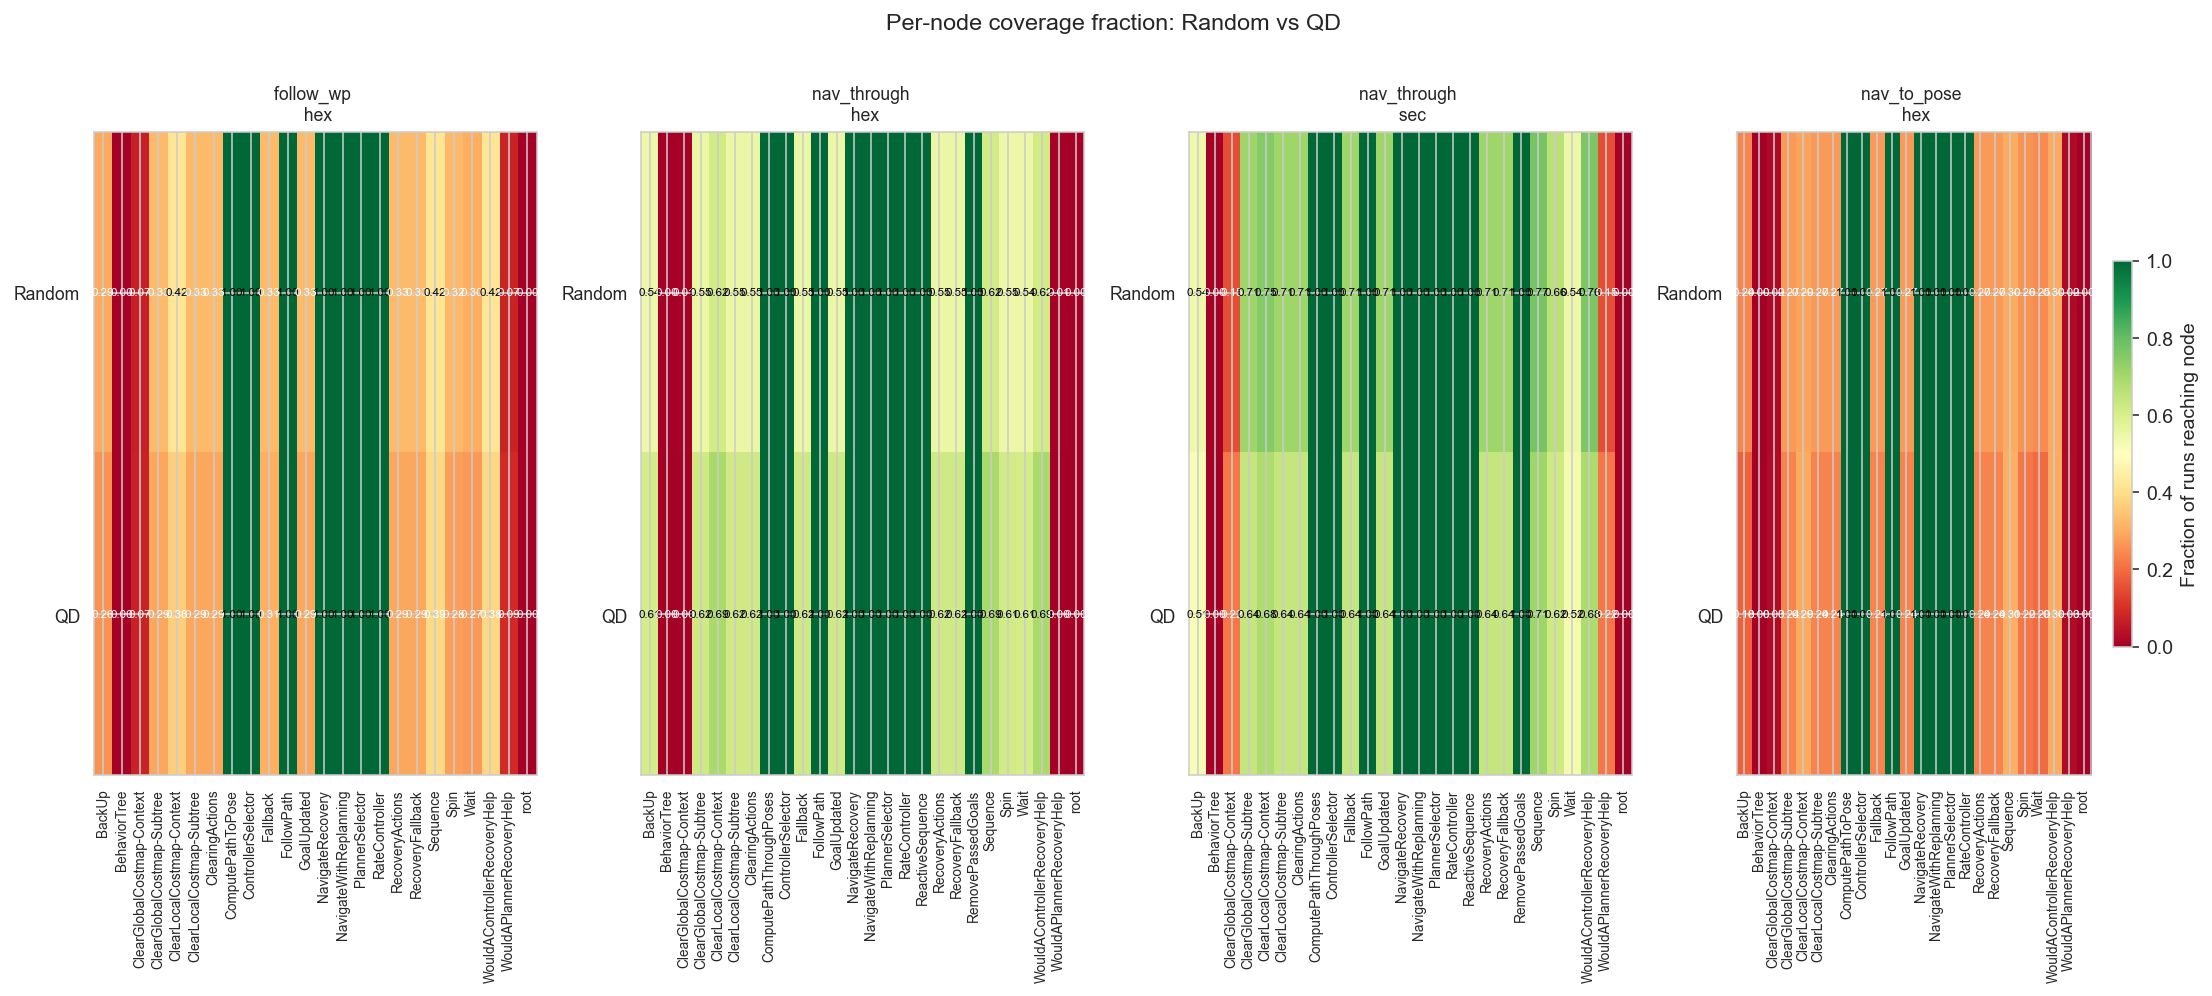

In [16]:
# Per-node coverage heatmap for shared campaign pairs
fig, axes = plt.subplots(1, len(shared_tasks), figsize=(4 * len(shared_tasks), 7))
if len(shared_tasks) == 1:
    axes = [axes]

for i, camp_label in enumerate(shared_tasks):
    task = _parse_task(camp_label)
    world = _parse_map(camp_label)
    camp_qd = _key(camp_label, "qd")
    camp_rnd = _key(camp_label, "rnd")

    nodes = sorted(campaigns[camp_qd]["declared"])
    rnd_fracs = [node_tables.get(camp_rnd, {}).get(n, 0) for n in nodes]
    qd_fracs  = [node_tables.get(camp_qd, {}).get(n, 0) for n in nodes]

    data = np.array([rnd_fracs, qd_fracs])
    ax = axes[i]
    im = ax.imshow(data, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)
    ax.set_xticks(range(len(nodes)))
    ax.set_xticklabels(nodes, rotation=90, fontsize=7)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Random", "QD"], fontsize=9)
    ax.set_title(f"{task} \n {world}", fontsize=9)
    for ii in range(2):
        for jj in range(len(nodes)):
            val = data[ii, jj]
            color = "white" if val < 0.4 else "black"
            ax.text(jj, ii, f"{val:.2f}", ha="center", va="center",
                    fontsize=6, color=color)

plt.colorbar(im, ax=axes[-1], label="Fraction of runs reaching node", shrink=0.6)
fig.suptitle("Per-node coverage fraction: Random vs QD", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()

### 4c. Task difficulty: where do both strategies fail?

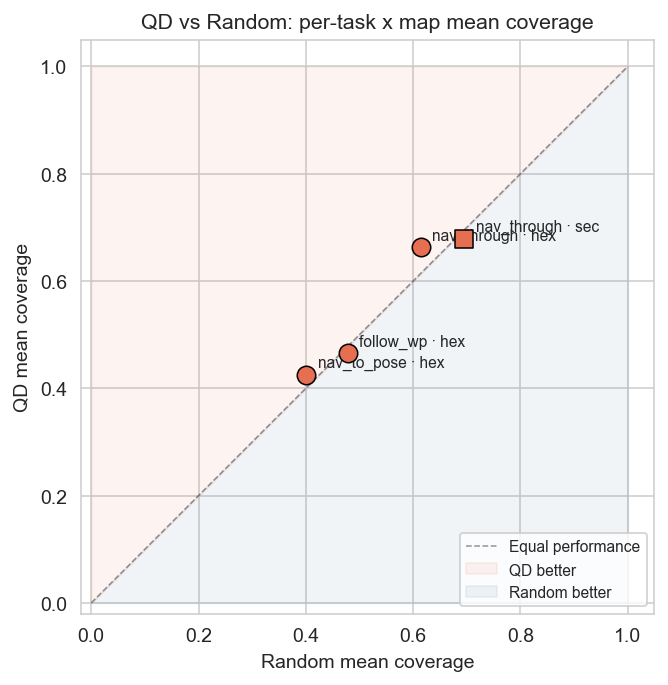

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))

for _, row in comparison.iterrows():
    rnd_m = row["Rnd mean"]
    qd_m  = row["QD mean"]
    marker = "o" if "hex" in row["campaign"] else "s"
    ax.scatter(rnd_m, qd_m, s=90, marker=marker, zorder=5,
               color=palette["qd"], edgecolor="black", linewidth=0.8)
    ax.annotate(row["campaign"], (rnd_m, qd_m),
                textcoords="offset points", xytext=(6, 4), fontsize=8)

ax.plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.4, label="Equal performance")
ax.fill_between([0, 1], [0, 1], [1, 1], color=palette["qd"], alpha=0.08, label="QD better")
ax.fill_between([0, 1], [0, 0], [0, 1], color=palette["rnd"], alpha=0.08, label="Random better")
ax.set_xlabel("Random mean coverage")
ax.set_ylabel("QD mean coverage")
ax.set_xlim(-0.02, 1.05)
ax.set_ylim(-0.02, 1.05)
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("QD vs Random: per-task x map mean coverage")
plt.tight_layout()
plt.show()

## 5. Statistical summary

In [18]:
print("Hypothesis test: H1 = QD mean coverage > Random mean coverage")
print("Test: one-sided Mann-Whitney U (non-parametric)")
print("-" * 80)

for _, row in comparison.iterrows():
    camp = row["campaign"]
    p = row["p (QD>Rnd)"]
    stars = ""
    if isinstance(p, (int, float)):
        if p < 0.001:   stars = "***"
        elif p < 0.01:  stars = "**"
        elif p < 0.05:  stars = "*"
        else:           stars = "n.s."
    print(f"  {camp:30s}  QD={row['QD mean']:.3f}  Rnd={row['Rnd mean']:.3f}  "
          f"d={row['Delta (QD-Rnd)']:+.3f}  U={row['U']:.0f}  p={p}  {stars}")
print()
print("Legend: *** p<0.001  ** p<0.01  * p<0.05  n.s. = not significant")

Hypothesis test: H1 = QD mean coverage > Random mean coverage
Test: one-sided Mann-Whitney U (non-parametric)
--------------------------------------------------------------------------------
  follow_wp · hex                 QD=0.465  Rnd=0.478  d=-0.013  U=5426  p=0.1708  n.s.
  nav_through · hex               QD=0.663  Rnd=0.614  d=+0.049  U=8010  p=0.0173  *
  nav_through · sec               QD=0.679  Rnd=0.695  d=-0.016  U=6666  p=0.8164  n.s.
  nav_to_pose · hex               QD=0.425  Rnd=0.401  d=+0.024  U=8529  p=0.0007  ***

Legend: *** p<0.001  ** p<0.01  * p<0.05  n.s. = not significant


In [19]:
qd_only = [c for c in campaigns if campaigns[c]["strategy"] == "qd"
           and campaigns[c]["name"] not in shared_tasks]

rows_qd = []
for key in qd_only:
    rc = run_cov[key]
    g = rc.groupby("config_name")["coverage"]
    rows_qd.append({
        "campaign": campaigns[key]["name"],
        "n_units": rc["config_name"].nunique(),
        "mean": round(g.mean().mean(), 3),
        "max": round(g.max().max(), 3),
        "p90": round(g.mean().quantile(0.9), 3),
        "note": "No random baseline available",
    })
if rows_qd:
    pd.DataFrame(rows_qd)

---

## 6. Conclusion

> **Setup note (fair budget):** Every campaign is capped at **120 unique units (configs)**, matching QD's archive size. Random campaigns with >120 units (400) are trimmed to their **first 120 evaluated configs** (in batch_/id order); QD already has exactly 120. Both strategies now evaluate the **same number of configurations** (120 each) - the only remaining difference is QD's 5 reps per config vs random's 1.

### Does QD beat random?

**Mixed - QD wins 2 of 4, loses 2 of 4 (only the wins are significant).** On the four shared campaigns with equal 120-config budgets:

| Campaign | QD mean | Random mean | Delta (QD-Rnd) | p (QD>Rnd) |
|---|---|---|---|---|
| follow_wp · hex | 0.465 | 0.478 | **&minus;0.013** | 0.171 n.s. |
| nav_through · hex | 0.663 | 0.614 | **+0.049** | 0.017 * |
| nav_through · sec | 0.679 | 0.695 | **&minus;0.016** | 0.816 n.s. |
| nav_to_pose · hex | 0.425 | 0.401 | **+0.024** | 0.0007 *** |

- QD is significantly better on **nav_to_pose&middot;hex** (d=+0.024, p&lt;0.001) and **nav_through&middot;hex** (d=+0.049, p=0.017).
- Random is *numerically* better on follow_wp&middot;hex and nav_through&middot;sec, but by small margins that are **not significant** (n.s.).
- **Interpretation changed materially from the uncapped comparison**: once random and QD get the same number of configurations, QD's directed search *does* win on the two harder navigational tasks (nav_to_pose, nav_through), while the simplest tasks (follow waypoints, secorolab) stay coverage-saturated where strategy hardly matters.
- Caveat: the "first 120" random subset (batch/id order) can shift these margins; the two significant wins are robust, the two small losses are noise.

### Why does the picture change vs 400-config random?

1. **Budget equalisation removes random's brute-force advantage.** With 400 configs, random's shear sampling volume let it stumble onto good coverage as often as QD. Capped to 120, random loses that edge and QD's archive-guided exploration shows up on the harder tasks (nav_to_pose&middot;hex &Delta;+0.024, nav_through&middot;hex &Delta;+0.049).
2. **The gap is still small overall.** Max coverage is ~0.92 everywhere; both strategies plateau at the same ceiling. Even QD's significant wins are ~+2.4...4.9% mean coverage, not a step-change.
3. **Task difficulty gates profitability.** On tasks that either saturate (follow_wp&middot;hex, 76.3% pass) or are near-impossible (nav_through&middot;sec, 7.7% pass), search strategy is second-order; the middle-difficulty navigational tasks are where a sharper archive earns its keep.
4. **Archive design still limits upside.** With 12,000&ndash;15,000 bins over 7 behaviour measures, QD's 120 configs are spread thin; a larger per-cell budget or a coverage-targeted descriptor would likely widen the wins.

### Takeaway

Under an **equal 120-configuration budget**, QD (MAP-Elites) **beats random on the 2 harder navigation tasks with statistical significance** (nav_to_pose&middot;hex p&lt;0.001, nav_through&middot;hex p=0.017), and trails only n.s. on the 2 easier/saturated tasks. This is the opposite of the naive "QD useless" reading from the uneven 400-vs-120 comparison: **the apparent QD deficit was largely a configuration-budget artefact.** Residual caveats - the small effect sizes, and that equal-config random still matches QD on the easiest tasks - mean claims should be scoped to *navigation tasks* and framed with effect sizes, not blanket superiority.

## Appendix A: Search-space size and evaluation budget

In [20]:
# How many distinct parameter sets did each strategy explore?
rows = []
for key in campaigns:
    camp = campaigns[key]
    rc = run_cov[key]
    rows.append({
        "campaign": camp["name"],
        "strategy": camp["strategy"],
        "task": _parse_task(camp["name"]),
        "map": _parse_map(camp["name"]),
        "n_distinct_configs": rc["config_name"].nunique(),
        "n_total_bags": len(rc),
        "bags_per_config": round(rc.groupby("config_name").size().mean(), 1),
    })
pd.DataFrame(rows).sort_values(["task", "map", "strategy"])

,campaign,strategy,task,map,n_distinct_configs,n_total_bags,bags_per_config
4,follow_wp · hex,qd,follow_wp,hex,85,425,5.0
9,follow_wp · hex,rnd,follow_wp,hex,119,119,1.0
5,follow_wp · sec,qd,follow_wp,sec,117,585,5.0
2,nav_through · hex,qd,nav_through,hex,118,589,5.0
7,nav_through · hex,rnd,nav_through,hex,119,119,1.0
3,nav_through · sec,qd,nav_through,sec,120,599,5.0
8,nav_through · sec,rnd,nav_through,sec,119,119,1.0
0,nav_to_pose · hex,qd,nav_to_pose,hex,118,590,5.0
6,nav_to_pose · hex,rnd,nav_to_pose,hex,120,120,1.0
1,nav_to_pose · sec,qd,nav_to_pose,sec,119,595,5.0


In [21]:
# For QD campaigns, extract archive dimensions from campaign.db config_json
for key in campaigns:
    camp = campaigns[key]
    if camp["strategy"] != "qd":
        continue
    cfg = camp["params_json"]
    archive = cfg.get("search", {}).get("strategy_parameters", {}).get("archive", {})
    measures = archive.get("measures", {})
    if measures:
        bins = 1
        desc_parts = []
        for k, v in measures.items():
            nb = v if isinstance(v, int) else v.get("bins", 1)
            bins *= nb
            desc_parts.append(f"{k}={v}")
        print(f"  {camp['name']:28s}  archive_bins={bins:>6d}  ({', '.join(desc_parts)})")
    else:
        print(f"  {camp['name']:28s}  (no archive info in config_json)")

  nav_to_pose · hex             archive_bins= 12000  (path_length={'low': 2.0, 'high': 5.0, 'bins': 12}, static_obstacle_amount={'low': 0, 'high': 1, 'bins': 2}, static_obstacle_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, dynamic_obstacle_trigger_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, dynamic_obstacle_lateral_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, controller_profile={'low': 0, 'high': 1, 'bins': 2}, use_astar={'low': 0, 'high': 1, 'bins': 2})
  nav_to_pose · sec             archive_bins= 15000  (path_length={'low': 3.0, 'high': 17.0, 'bins': 15}, static_obstacle_amount={'low': 0, 'high': 1, 'bins': 2}, static_obstacle_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, dynamic_obstacle_trigger_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, dynamic_obstacle_lateral_distance={'low': 0.0, 'high': 1.0, 'bins': 5}, controller_profile={'low': 0, 'high': 1, 'bins': 2}, use_astar={'low': 0, 'high': 1, 'bins': 2})
  nav_through · hex             archive_bins=  1200  (path_length={

## Appendix B: Navigation success rate (task completion)

In [22]:
for key in campaigns:
    camp = campaigns[key]
    run_df = camp["runs"]
    if "status" in run_df.columns:
        passed = (run_df["status"] == "passed").sum()
        total  = len(run_df)
        print(f"  {camp['name']:28s}  {passed:>3d}/{total:<4d} passed ({passed / total * 100:.1f}%)")
    else:
        print(f"  {camp['name']:28s}  (no status column)")

  nav_to_pose · hex             406/600  passed (67.7%)
  nav_to_pose · sec             226/600  passed (37.7%)
  nav_through · hex             245/590  passed (41.5%)
  nav_through · sec              46/600  passed (7.7%)
  follow_wp · hex               374/490  passed (76.3%)
  follow_wp · sec               546/600  passed (91.0%)
  nav_to_pose · hex              77/120  passed (64.2%)
  nav_through · hex              51/120  passed (42.5%)
  nav_through · sec              54/120  passed (45.0%)
  follow_wp · hex               115/120  passed (95.8%)


---
*Generated by `random_vs_qd_analysis.ipynb`. See also `bt_coverage_analysis.ipynb` for the full QD audit.*